# I. Environment and Data Cleaning

In [1]:
from pathlib import Path
from itertools import product
import hashlib
import importlib.metadata
import json
import sys

import numpy as np
import pandas as pd
from scipy.optimize import Bounds, check_grad, minimize
from scipy.special import ndtr
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebook":
    ROOT = ROOT.parent
TABLES = ROOT / "results_1/tables"
FIGURES = ROOT / "results_1/figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
assert TABLES.resolve().is_relative_to(ROOT / "results_1")
assert FIGURES.resolve().is_relative_to(ROOT / "results_1")
plt.rcParams.update({"font.size": 9, "axes.grid": True, "grid.alpha": .2, "figure.dpi": 110})
COLORS = {"baseline": "#245a9a", "ridge": "#c45a22"}


def export(name, frame):
    """All numerical exports share one fixed, protected destination."""
    assert Path(name).name == name and name.endswith(".csv")
    frame.to_csv(TABLES / name, index=False, date_format="%Y-%m-%d", float_format="%.17g")


def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / (name + ".png"), dpi=200, bbox_inches="tight")
    display(fig)
    plt.close(fig)

In [2]:

# Load the original datasets
option_source = pd.read_csv(ROOT / "data/options_data.csv")
future_source = pd.read_csv(ROOT / "data/spx_futures.csv")

options = option_source.copy()
futures = future_source.copy()


# Check required columns
option_key = ["pricedate", "Expiry", "strike", "option_type"]

required_option_columns = option_key + ["impliedvol"]
required_future_columns = ["query_date", "ID", "fut_last_trade_dt()", "px_last(dates=#dt)"]

assert set(required_option_columns).issubset(options.columns)
assert set(required_future_columns).issubset(futures.columns)

In [3]:
# Convert dates and numerical columns
for column in ["pricedate", "Expiry"]:
    options[column] = pd.to_datetime(options[column], format="%d/%m/%Y", errors="raise")

for column in ["query_date", "fut_last_trade_dt()"]:
    futures[column] = pd.to_datetime(futures[column], format="%Y-%m-%d", errors="raise")

for column in ["strike", "impliedvol"]:
    options[column] = pd.to_numeric(options[column], errors="raise")

futures["px_last(dates=#dt)"] = pd.to_numeric(
    futures["px_last(dates=#dt)"], errors="raise"
)

options["source_record"] = np.arange(1, len(options) + 1)
options["iv_decimal"] = options["impliedvol"] / 100

In [4]:
# Validate the original data
assert options[option_key].notna().all().all()
assert not options.duplicated(option_key).any()
assert not futures.duplicated(["query_date", "ID"]).any()

assert options["option_type"].isin(["Call", "Put"]).all()
assert np.isfinite(options["strike"]).all()
assert (options["strike"] > 0).all()
assert (options["Expiry"] > options["pricedate"]).all()

reported_iv = options["impliedvol"].dropna()
reported_forward = futures["px_last(dates=#dt)"].dropna()

assert np.isfinite(reported_iv).all()
assert (reported_iv > 0).all()

assert np.isfinite(reported_forward).all()
assert (reported_forward > 0).all()

In [5]:
# Remove observations with missing IV
missing_iv = options["impliedvol"].isna()

clean = options.loc[~missing_iv].copy().reset_index(drop=True)
excluded = options.loc[missing_iv].copy()

excluded["exclusion_reason"] = "missing_impliedvol"

ledger = options.copy()
ledger["cleaning_status"] = np.where(
    missing_iv, "missing_impliedvol", "retained"
)


In [6]:
# Verify cleaning results
assert len(options) == 44234
assert len(excluded) == 2074
assert len(clean) == 42160
assert clean["pricedate"].nunique() == 103

assert set(clean["source_record"]).isdisjoint(excluded["source_record"])

all_records = pd.concat([
    clean["source_record"],
    excluded["source_record"]
])

assert sorted(all_records) == list(options["source_record"])

assert options["Expiry"].nunique() == 1
assert options["Expiry"].iloc[0] == pd.Timestamp("2026-12-18")

In [7]:
# Calculate option data coverage
coverage = (
    options.groupby(["pricedate", "option_type"])["impliedvol"]
    .agg(rows="size", nonmissing="count")
    .reset_index()
)

coverage["missing"] = coverage["rows"] - coverage["nonmissing"]

In [8]:
# Record source schemas
schema_rows = []

datasets = [
    ("options", option_source, options),
    ("futures", future_source, futures)
]

for name, original, parsed in datasets:
    for column in original.columns:
        schema_rows.append({
            "dataset": name,
            "column": column,
            "source_dtype": str(original[column].dtype),
            "parsed_dtype": str(parsed[column].dtype),
            "missing_count": int(parsed[column].isna().sum())
        })

schema = pd.DataFrame(schema_rows)

# Record input file information and hashes
input_rows = []

input_files = [
    ("data/options_data.csv", options),
    ("data/spx_futures.csv", futures)
]

for filename, frame in input_files:
    path = ROOT / filename

    input_rows.append({
        "path": filename,
        "rows": len(frame),
        "sha256": hashlib.sha256(path.read_bytes()).hexdigest()
    })

inputs = pd.DataFrame(input_rows)



# Record Python and library versions
environment_rows = [
    {"component": "python", "version": sys.version.split()[0]}
]

packages = ["numpy", "pandas", "scipy", "matplotlib", "nbclient", "nbformat"]

for package in packages:
    try:
        version = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        version = "not installed"

    environment_rows.append({
        "component": package,
        "version": version
    })

environment = pd.DataFrame(environment_rows)

display(environment)


# Record source integrity checks
integrity_checks = [
    ("option_duplicate_keys", options.duplicated(option_key).sum()),
    ("futures_duplicate_keys", futures.duplicated(["query_date", "ID"]).sum()),
    ("option_nonpositive_strikes", (options["strike"] <= 0).sum()),
    ("option_nonpositive_reported_iv", (reported_iv <= 0).sum()),
    ("option_nonfinite_reported_iv", (~np.isfinite(reported_iv)).sum()),
    ("option_expired_on_pricing_date", (options["Expiry"] <= options["pricedate"]).sum()),
    ("futures_nonpositive_reported_last", (reported_forward <= 0).sum()),
    ("futures_nonfinite_reported_last", (~np.isfinite(reported_forward)).sum())
]

source_integrity = pd.DataFrame(
    integrity_checks,
    columns=["check", "invalid_count"]
)

source_integrity["invalid_count"] = source_integrity["invalid_count"].astype(int)

,component,version
0,python,3.9.6
1,numpy,2.0.2
2,pandas,2.3.3
3,scipy,1.13.1
4,matplotlib,3.9.4
5,nbclient,not installed
6,nbformat,not installed


In [9]:
# Calculate futures data coverage
futures_coverage = (
    futures.groupby("ID")
    .agg(
        rows=("query_date", "size"),
        dates=("query_date", "nunique"),
        first_date=("query_date", "min"),
        last_date=("query_date", "max"),
        nonmissing_last=("px_last(dates=#dt)", "count")
    )
    .reset_index()
)

futures_coverage["missing_last"] = (
    futures_coverage["rows"] - futures_coverage["nonmissing_last"]
)

In [10]:
# Export all results
export("source_ledger.csv", ledger)
export("excluded_missing_iv.csv", excluded)
export("cleaned_options.csv", clean)
export("source_schema.csv", schema)
export("data_coverage.csv", coverage)
export("input_manifest.csv", inputs)
export("environment.csv", environment)
export("source_integrity.csv", source_integrity)
export("futures_coverage.csv", futures_coverage)


# Display the cleaning summary
summary = pd.DataFrame({
    "source_rows": [len(options)],
    "missing_IV": [len(excluded)],
    "retained": [len(clean)]
})

display(summary)


,source_rows,missing_IV,retained
0,44234,2074,42160


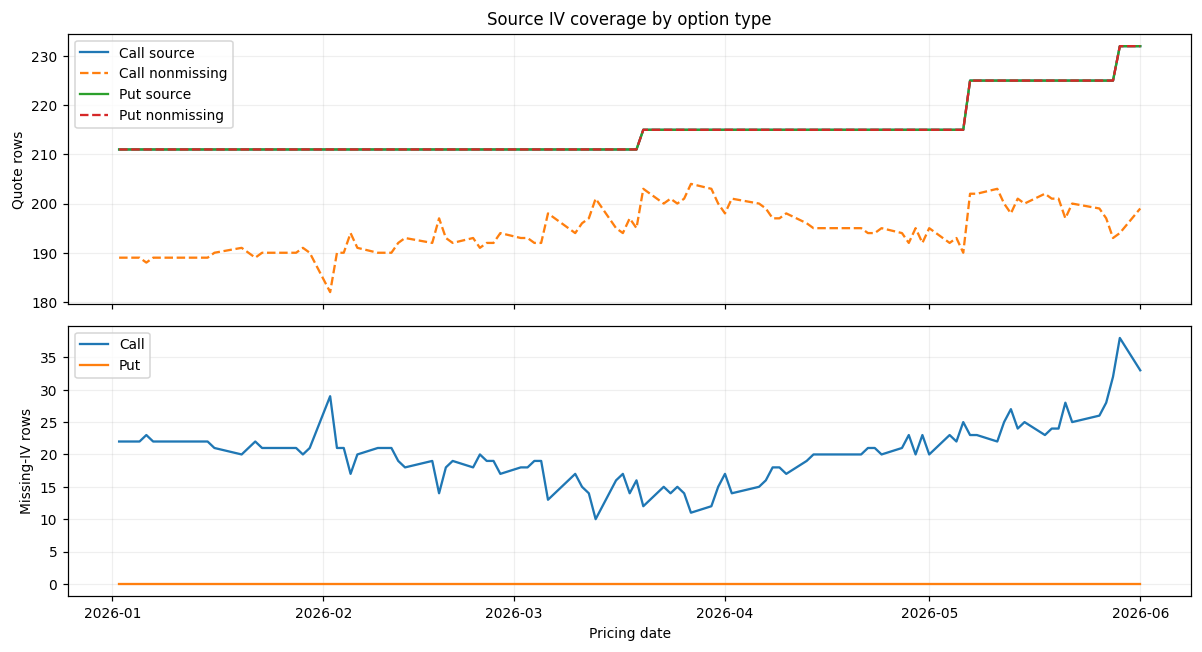

In [11]:
# Create two plots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

# Plot calls and puts
for option_type in ["Call", "Put"]:
    data = coverage[coverage["option_type"] == option_type]

    ax1.plot(data["pricedate"], data["rows"], label=option_type + " source")
    ax1.plot(data["pricedate"], data["nonmissing"], "--",
             label=option_type + " nonmissing")

    ax2.plot(data["pricedate"], data["missing"], label=option_type)

# Add titles and labels
ax1.set_title("Source IV coverage by option type")
ax1.set_ylabel("Quote rows")
ax1.legend()

ax2.set_xlabel("Pricing date")
ax2.set_ylabel("Missing-IV rows")
ax2.legend()

# Save and display
save_figure(fig, "01_data_coverage")


# II. Calibration Setup

## 1. Log Moneyness and Total Implied Variance

In [12]:
# Select ESZ26 futures prices

forward = futures[futures["ID"] == "ESZ26 Index"].copy()
forward = forward[["query_date", "px_last(dates=#dt)"]]
forward = forward.rename(columns={
    "query_date": "forward_date",
    "px_last(dates=#dt)": "F"
})

assert len(forward) > 0
assert not forward["forward_date"].duplicated().any()

# Match futures prices to options
quotes = pd.merge(
    clean,
    forward,
    left_on="pricedate",
    right_on="forward_date",
    how="left",
    validate="many_to_one"
)

assert len(quotes) == len(clean)
assert quotes["source_record"].tolist() == clean["source_record"].tolist()
assert (quotes["forward_date"] == quotes["pricedate"]).all()
assert np.isfinite(quotes["F"]).all()
assert (quotes["F"] > 0).all()


# Calculate time to maturity
quotes["maturity_days"] = (quotes["Expiry"] - quotes["pricedate"]).dt.days
quotes["T"] = quotes["maturity_days"] / 365
assert np.isfinite(quotes["T"]).all()
assert (quotes["T"] > 0).all()


# Record forward prices and maturities
forward_audit = quotes.groupby("pricedate").agg(
    rows=("source_record", "size"),
    F=("F", "first"),
    maturity_days=("maturity_days", "first"),
    T=("T", "first")
).reset_index()

export("forward_maturity_by_date.csv", forward_audit)

In [13]:
# Calculate log-moneyness and total implied variance
quotes["k"] = np.log(quotes["strike"] / quotes["F"])
quotes["w_market"] = quotes["iv_decimal"] ** 2 * quotes["T"]

assert np.isfinite(quotes["k"]).all()
assert np.isfinite(quotes["w_market"]).all()
assert (quotes["w_market"] > 0).all()


# Verify the calculations
np.testing.assert_allclose(
    quotes["F"] * np.exp(quotes["k"]),
    quotes["strike"],
    rtol=1e-12,
    atol=0
)

np.testing.assert_allclose(
    np.sqrt(quotes["w_market"] / quotes["T"]),
    quotes["iv_decimal"],
    rtol=1e-12,
    atol=0
)

# Identify out-of-the-money options
otm_put = (
    (quotes["option_type"] == "Put") &
    (quotes["strike"] < quotes["F"])
)

otm_call = (
    (quotes["option_type"] == "Call") &
    (quotes["strike"] > quotes["F"])
)

quotes["selected"] = otm_put | otm_call

quotes["selection_reason"] = "non_otm_side"

quotes.loc[otm_put, "selection_reason"] = "otm_put"
quotes.loc[otm_call, "selection_reason"] = "otm_call"

quotes.loc[
    quotes["strike"] == quotes["F"],
    "selection_reason"
] = "exact_forward"

In [14]:
# Create the calibration sample
sample = quotes[quotes["selected"]].copy()

sample = sample.sort_values(
    ["pricedate", "k", "source_record"],
    kind="stable"
).reset_index(drop=True)

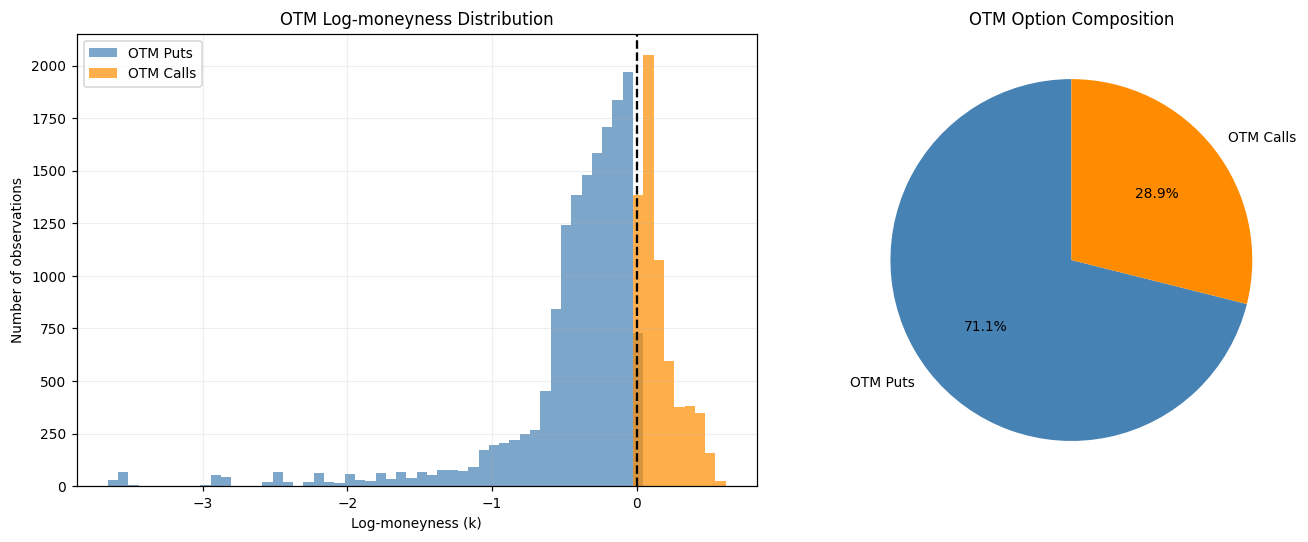

Minimum observed k: -3.6557749984658954
Maximum observed k: 0.6155690459145706
OTM puts: 15722
OTM calls: 6394


In [15]:
# Plot OTM log-moneyness distribution and option composition
puts = sample.loc[sample["selection_reason"] == "otm_put", "k"]
calls = sample.loc[sample["selection_reason"] == "otm_call", "k"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Distribution of log-moneyness
bins = np.linspace(sample["k"].min(), sample["k"].max(), 61)

axes[0].hist(puts, bins=bins, color="steelblue",
             alpha=0.7, label="OTM Puts")
axes[0].hist(calls, bins=bins, color="darkorange",
             alpha=0.7, label="OTM Calls")

axes[0].axvline(0, color="black", linestyle="--")
axes[0].set_xlabel("Log-moneyness (k)")
axes[0].set_ylabel("Number of observations")
axes[0].set_title("OTM Log-moneyness Distribution")
axes[0].legend()

# 2. Put vs call composition
axes[1].pie(
    [len(puts), len(calls)],
    labels=["OTM Puts", "OTM Calls"],
    colors=["steelblue", "darkorange"],
    autopct="%1.1f%%",
    startangle=90
)
axes[1].set_title("OTM Option Composition")

plt.tight_layout()
plt.show()

print("Minimum observed k:", sample["k"].min())
print("Maximum observed k:", sample["k"].max())
print("OTM puts:", len(puts))
print("OTM calls:", len(calls))

In [19]:
# Organize observations by pricing date
days = sorted(sample["pricedate"].unique())

daily_inputs = {}

for date, data in sample.groupby("pricedate", sort=True):
    daily_inputs[date] = data


# Calculate calibration coverage
calibration_coverage = (
    sample.groupby(["pricedate", "option_type"])
    .size()
    .reset_index(name="rows")
)

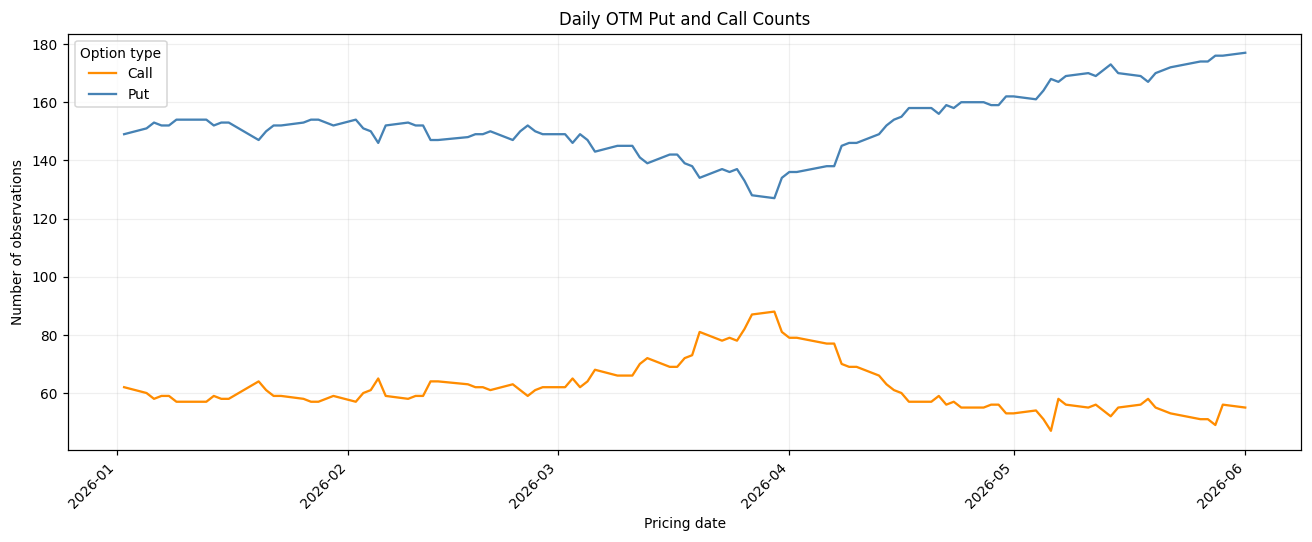

Number of pricing dates: 103


In [21]:
# Plot daily OTM put and call counts
coverage_plot = (
    calibration_coverage
    .pivot(index="pricedate", columns="option_type", values="rows")
    .fillna(0)
    .sort_index()
)

ax = coverage_plot.plot(
    figsize=(12, 5),
    color=["darkorange", "steelblue"],
    linewidth=1.5
)

ax.set_xlabel("Pricing date")
ax.set_ylabel("Number of observations")
ax.set_title("Daily OTM Put and Call Counts")
ax.legend(title="Option type")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Number of pricing dates:", len(days))

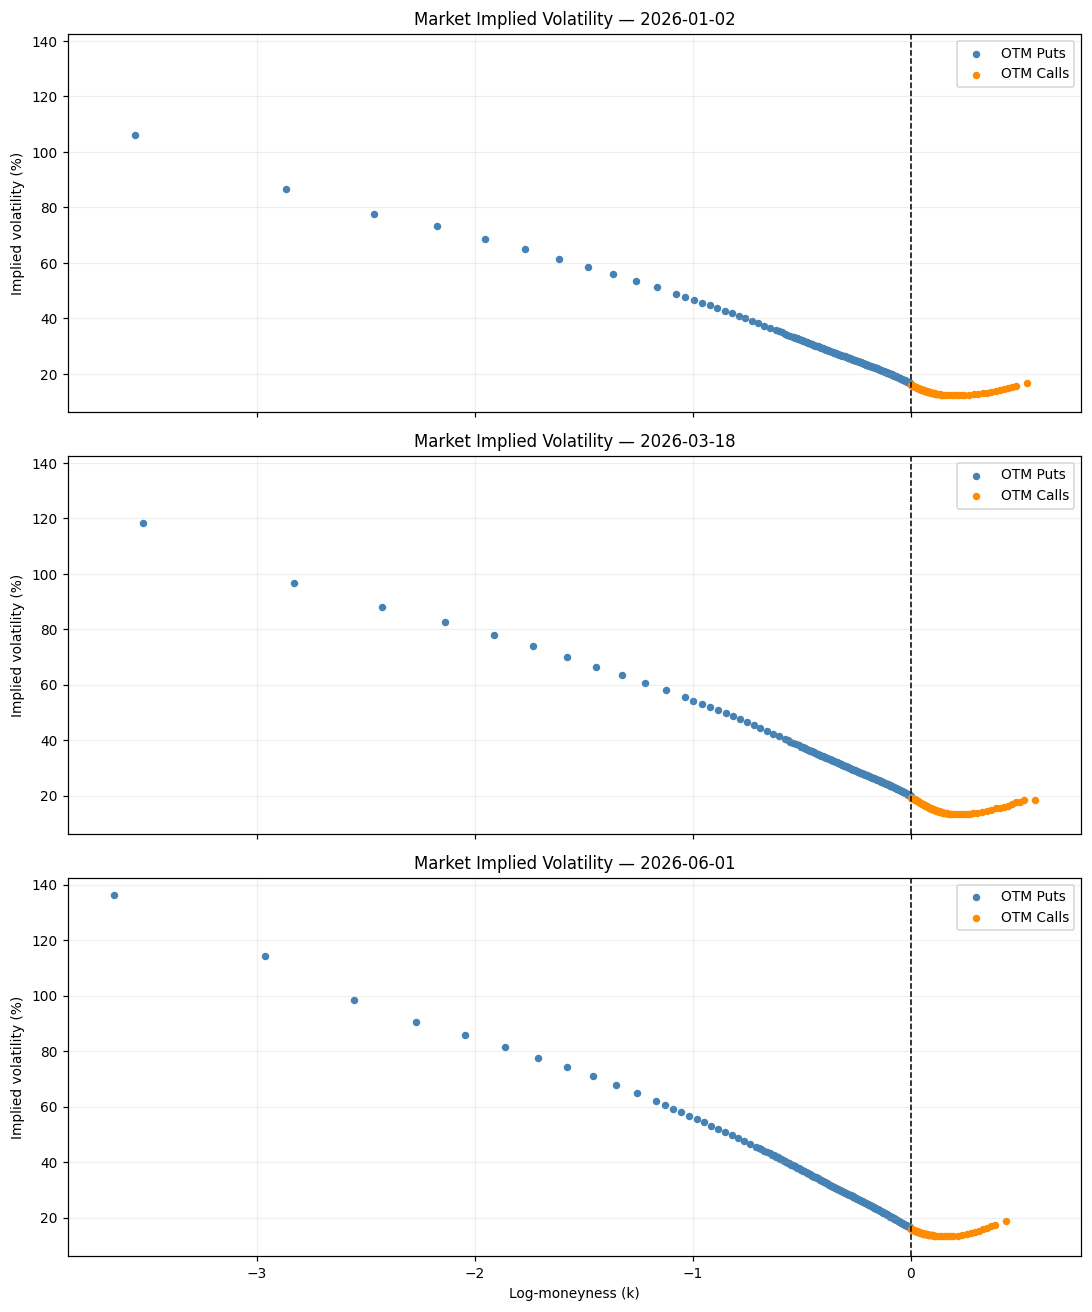

In [23]:
# Plot market implied volatility for the first, middle, and last dates
selected_days = [days[0], days[len(days)//2], days[-1]]

fig, axes = plt.subplots(3, 1, figsize=(10, 12), sharex=True, sharey=True)

for ax, date in zip(axes, selected_days):
    data = daily_inputs[date]

    puts = data[data["option_type"] == "Put"]
    calls = data[data["option_type"] == "Call"]

    ax.scatter(puts["k"], puts["iv_decimal"] * 100,
               color="steelblue", s=15, label="OTM Puts")

    ax.scatter(calls["k"], calls["iv_decimal"] * 100,
               color="darkorange", s=15, label="OTM Calls")

    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.set_ylabel("Implied volatility (%)")
    ax.set_title(f"Market Implied Volatility — {date:%Y-%m-%d}")
    ax.legend()

axes[-1].set_xlabel("Log-moneyness (k)")

plt.tight_layout()
plt.show()

## 2. Parameter Settings

In [24]:
# SVI parameters and optimizer settings
RAW = ["a", "b", "rho", "m", "s"]
COORD = ["q_v", "q_b", "q_r", "q_m", "q_ell"]

# L-BFGS-B settings
METHOD = "L-BFGS-B"
SOLVER = {
    "ftol": 1e-12,
    "gtol": 1e-8,
    "maxiter": 2000,
    "maxfun": 20000,
    "maxls": 50,
    "maxcor": 10
}
BOUNDS = Bounds(
    [0, 0, -np.inf, -0.5, -np.inf],
    [np.inf, np.inf, np.inf, 0.5, np.inf]
)

# Multistart settings
RHO_STARTS = [-0.8, 0, 0.8]
S_STARTS = [0.05, 0.2, 1]


Add parameters here

In [69]:

# Calculate SVI total implied variance
def svi(k, theta):
    a, b, rho, m, s = theta
    x = np.asarray(k, dtype=float) - m
    return a + b * (rho*x + np.hypot(x, s))


# Calculate minimum SVI variance
def minimum_variance(theta):
    a, b, rho, m, s = theta
    return float(a + b*s*np.sqrt(1-rho**2))


# Convert optimizer coordinates to SVI parameters
def to_raw(q):
    q = np.asarray(q, dtype=float)
    if q.shape != (5,) or not np.isfinite(q).all() or (q[:2] < 0).any():
        raise ValueError("Require finite q and nonnegative v,b")

    v, b, r, m, ell = q
    with np.errstate(over="raise", invalid="raise", under="ignore"):
        rho, s = np.tanh(r), np.exp(ell)
        a = v - b*s*np.sqrt(1-rho**2)

    theta = np.array([a, b, rho, m, s])
    if not feasible(theta):
        raise ValueError("Mapped parameters are outside the representable SVI domain")
    return theta


# Convert SVI parameters to optimizer coordinates
def to_coordinates(theta):
    if not feasible(theta):
        raise ValueError("Infeasible raw parameters")

    a, b, rho, m, s = theta
    return np.array([minimum_variance(theta), b, np.arctanh(rho), m, np.log(s)])


# Calculate fitting loss and analytical gradient
PSEUDO_HUBER_DELTA = 0.005

def loss_gradient(q, k, market_w):
    a, b, rho, m, s = to_raw(q)

    with np.errstate(over="raise", invalid="raise", divide="raise"):
        x, c = k-m, np.sqrt(1-rho**2)
        h = np.hypot(x, s)
        residual = svi(k, [a,b,rho,m,s]) - market_w

        jacobian = np.column_stack([
            np.ones_like(k),
            rho*x+h-s*c,
            b*(c**2*x+s*rho*c),
            -b*(rho+x/h),
            b*s*(s/h-c)
        ])

        delta = PSEUDO_HUBER_DELTA

        loss = float(np.mean(
            delta**2 * (np.hypot(1.0, residual/delta) - 1.0)
        ))

        weights = residual / np.hypot(1.0, residual/delta)
        gradient = (1.0/k.size) * (jacobian.T @ weights)

    if not np.isfinite(loss) or not np.isfinite(gradient).all():
        raise FloatingPointError("Nonfinite loss or gradient")

    return loss, gradient

In [70]:
# Check whether SVI parameters are valid
def feasible(theta):
    if not np.isfinite(theta).all():
        return False

    a, b, rho, m, s = theta

    if b < 0 or not -1 < rho < 1 or s <= 0:
        return False

    with np.errstate(over="ignore", invalid="ignore"):
        v = minimum_variance(theta)

    return bool(np.isfinite(v) and v >= 0)

# Create synthetic data for mathematical checks
synthetic_k = np.array([-1.0, -0.25, 0.0, 0.1, 0.6])
synthetic_w = 0.02 + 0.03 * synthetic_k**2
cases = {
    "interior": [0.01, 0.1, -0.5, 0.0, np.log(0.2)],
    "zero_minimum": [0.0, 0.1, 0.5, -0.1, np.log(0.2)],
    "b_zero": [0.01, 0.0, -0.5, 1.5, np.log(0.2)],
    "both_zero": [0.0, 0.0, 0.8, -0.4, np.log(0.15)],
    "interior_second": [0.02, 0.3, 2.0, 0.2, np.log(0.8)]
}

# Check parameter conversion, minimum variance, and gradient
math_checks = []
for name, values in cases.items():
    q = np.array(values)
    theta = to_raw(q)

    # Check conversion back to optimizer coordinates
    recovered_q = to_coordinates(theta)
    np.testing.assert_allclose(recovered_q, q, rtol=1e-12, atol=1e-14)

    # Check minimum total variance
    a, b, rho, m, s = theta
    k_min = m - rho * s / np.sqrt(1 - rho**2)
    np.testing.assert_allclose(svi(k_min, theta), q[0], rtol=1e-12, atol=1e-14)

    # Check that b = 0 produces a constant curve
    if b == 0:
        expected_w = np.full(5, q[0])
        np.testing.assert_array_equal(svi(synthetic_k, theta), expected_w)

    # Compare analytical and numerical gradients
    def loss_only(q):
        return loss_gradient(q, synthetic_k, synthetic_w)[0]
    def gradient_only(q):
        return loss_gradient(q, synthetic_k, synthetic_w)[1]
    error = check_grad(loss_only, gradient_only, q, epsilon=1e-7)
    assert error <= 1e-6
    math_checks.append({
        "check": name,
        "error": error,
        "tolerance": 1e-6,
        "passed": True
    })

# Check that invalid parameter inputs are rejected
invalid_cases = [
    [-1, 0.1, 0, 0, 0],
    [0.01, -0.1, 0, 0, 0],
    [0.01, 0.1, 1000, 0, 0],
    [0.01, 0.1, 0, 0, 1000],
    [0.01, 0.1, 0, 0, -1000]
]
for q in invalid_cases:
    try:
        to_raw(q)
    except (ValueError, ArithmeticError):
        continue
    raise AssertionError("Invalid parameters were accepted")

# Save and display mathematical checks
math_checks = pd.DataFrame(math_checks)
export("baseline_mathematical_checks.csv", math_checks)
display(math_checks)

,check,error,tolerance,passed
0,interior,9.096011e-09,0.000001,True
1,zero_minimum,1.094641e-08,0.000001,True
2,b_zero,1.067468e-08,0.000001,True
3,both_zero,4.965488e-10,0.000001,True
4,interior_second,1.424239e-09,0.000001,True


## 3. Optimisation Settings

In [71]:
# Generate the original 29 starting points
def starts(k, market_w):
    b_scale = np.ptp(market_w) / np.ptp(k)

    points = [
        (0.5*market_w.min(), b_scale, np.arctanh(rho), m, np.log(s))
        for rho, m, s in product(
            [-0.8, 0.0, 0.8],
            [k.min(), 0.0, k.max()],
            [0.05, 0.2, 1.0]
        )
    ]

    points += [
        (market_w.mean(), 0.0, 0.0, 0.0, np.log(0.2)),
        (0.0, b_scale, 0.0, 0.0, np.log(0.2))
    ]

    return [np.asarray(q, dtype=float) for q in points]


In [72]:
# Optimize baseline SVI using multistart 
def optimize_starts_base(date, k, market_w):
    points = starts(k, market_w)
    attempts = []
    for start_id, q0 in enumerate(points, 1):
        row = {
            "pricedate": date, "lambda_value": 0, "start_id": start_id,
            "selected": False, "eligible": False, "solver_success": False,
            "feasible": False, "reference_date": None,
            "solver_status": np.nan, "solver_message": np.nan,
            "n_iter": 0, "n_eval": 0, "n_jac_eval": 0,
            "data_mse": np.nan, "unweighted_penalty": np.nan,
            "penalty": np.nan, "total_objective": np.nan,
            "reported_objective": np.nan, "outcome": np.nan,
            "last_valid_objective": np.nan
        }
        row.update(dict.fromkeys(RAW + COORD, np.nan))
        row.update(dict(zip(["initial_" + c for c in COORD], q0)))
        progress = {"n_eval": 0, "n_iter": 0, "last_q": np.array(q0, copy=True), "last_value": np.nan}

        # Track objective evaluations and iterations
        def objective(q):
            progress["n_eval"] += 1
            progress["last_q"] = np.array(q, copy=True)
            value, gradient = loss_gradient(q, k, market_w)
            progress["last_value"] = value
            return value, gradient

        def callback(q):
            progress["n_iter"] += 1

        # Fit baseline SVI
        try:
            result = minimize(
                objective, q0, method=METHOD, jac=True,
                bounds=BOUNDS, callback=callback, options=SOLVER
            )
            theta = to_raw(result.x)
            mse, _ = loss_gradient(result.x, k, market_w)
            valid = feasible(theta)
            accepted = bool(result.success and np.isfinite(result.fun) and np.isfinite(mse) and valid)
            row.update({
                "solver_success": bool(result.success),
                "feasible": valid,
                "eligible": accepted,
                "solver_status": int(result.status),
                "solver_message": str(result.message),
                "n_iter": int(result.nit),
                "n_eval": int(result.nfev),
                "n_jac_eval": int(result.njev),
                "data_mse": mse,
                "unweighted_penalty": 0,
                "penalty": 0,
                "total_objective": mse,
                "reported_objective": float(result.fun),
                "outcome": "converged_eligible" if accepted else "nonconverged_finite_feasible"
            })
            row.update(dict(zip(RAW, theta)))
            row.update(dict(zip(COORD, result.x)))
        except (ValueError, ArithmeticError) as error:
            row.update({
                "outcome": "numerical_exception",
                "solver_message": f"{type(error).__name__}: {error}",
                "n_iter": progress["n_iter"],
                "n_eval": progress["n_eval"]
            })
        row["last_valid_objective"] = progress["last_value"]
        row.update(dict(zip(["last_requested_" + c for c in COORD], progress["last_q"])))
        attempts.append(row)

    # Select the eligible result with the lowest MSE
    eligible = [row for row in attempts if row["eligible"]]
    best = min(eligible, key=lambda row: (row["total_objective"], row["start_id"])) if eligible else None
    if best is not None:
        best["selected"] = True
    return best, attempts

In [73]:
# Optimize ridge SVI using 30 starting points and temporal penalization
def optimize_starts_ridge(date, k, market_w, lam, reference_q, reference_date, scales):
    points = starts(k, market_w)
    points.append(np.array(reference_q, copy=True))
    reference = to_raw(reference_q)
    attempts = []
    for start_id, q0 in enumerate(points, 1):
        row = {
            "pricedate": date, "lambda_value": lam, "start_id": start_id,
            "selected": False, "eligible": False, "solver_success": False,
            "feasible": False, "reference_date": reference_date,
            "solver_status": np.nan, "solver_message": np.nan,
            "n_iter": 0, "n_eval": 0, "n_jac_eval": 0,
            "data_mse": np.nan, "unweighted_penalty": np.nan,
            "penalty": np.nan, "total_objective": np.nan,
            "reported_objective": np.nan, "outcome": np.nan,
            "last_valid_objective": np.nan
        }
        row.update(dict.fromkeys(RAW + COORD, np.nan))
        row.update(dict(zip(["initial_" + c for c in COORD], q0)))
        progress = {"n_eval": 0, "n_iter": 0, "last_q": np.array(q0, copy=True), "last_value": np.nan}

        # Track the penalized objective and iterations
        def objective(q):
            progress["n_eval"] += 1
            progress["last_q"] = np.array(q, copy=True)
            value, gradient, _, _ = ridge_gradient(q, k, market_w, reference, lam, scales)
            progress["last_value"] = value
            return value, gradient

        def callback(q):
            progress["n_iter"] += 1

        # Fit ridge SVI
        try:
            result = minimize(
                objective, q0, method=METHOD, jac=True,
                bounds=BOUNDS, callback=callback, options=SOLVER
            )
            theta = to_raw(result.x)
            total, _, mse, penalty = ridge_gradient(
                result.x, k, market_w, reference, lam, scales
            )
            unweighted = float(np.sum(((theta - reference) / scales) ** 2))
            valid = feasible(theta)
            accepted = bool(result.success and np.isfinite(result.fun) and np.isfinite(total) and valid)
            row.update({
                "solver_success": bool(result.success),
                "feasible": valid,
                "eligible": accepted,
                "solver_status": int(result.status),
                "solver_message": str(result.message),
                "n_iter": int(result.nit),
                "n_eval": int(result.nfev),
                "n_jac_eval": int(result.njev),
                "data_mse": mse,
                "unweighted_penalty": unweighted,
                "penalty": penalty,
                "total_objective": total,
                "reported_objective": float(result.fun),
                "outcome": "converged_eligible" if accepted else "nonconverged_finite_feasible"
            })
            row.update(dict(zip(RAW, theta)))
            row.update(dict(zip(COORD, result.x)))
        except (ValueError, ArithmeticError) as error:
            row.update({
                "outcome": "numerical_exception",
                "solver_message": f"{type(error).__name__}: {error}",
                "n_iter": progress["n_iter"],
                "n_eval": progress["n_eval"]
            })
        row["last_valid_objective"] = progress["last_value"]
        row.update(dict(zip(["last_requested_" + c for c in COORD], progress["last_q"])))
        attempts.append(row)

    # Select the eligible result with the lowest penalized objective
    eligible = [row for row in attempts if row["eligible"]]
    best = min(eligible, key=lambda row: (row["total_objective"], row["start_id"])) if eligible else None
    if best is not None:
        best["selected"] = True
    return best, attempts


# III. Calibratrion

## 1. Baseline SVI Calibration

In [74]:
# Fit baseline SVI for one trading date
def fit_day_base(date, k, market_w):
    best, attempts = optimize_starts_base(date, k, market_w)
    eligible = sum(row["eligible"] for row in attempts)

    # Store the daily baseline result
    state = {
        "pricedate": date,
        "lambda_value": 0,
        "fit_status": "available" if best else "unavailable_all_starts_failed",
        "n_observations": len(k),
        "n_attempts": len(attempts),
        "n_eligible": eligible,
        "n_numerical_exceptions": sum(row["outcome"] == "numerical_exception" for row in attempts),
        "reference_date": None,
        "reference_gap_days": np.nan,
        "selected_start_id": best["start_id"] if best else np.nan
    }
    for field in RAW + COORD + ["data_mse", "unweighted_penalty", "penalty", "total_objective"]:
        state[field] = best[field] if best else np.nan
    state["raw_minimum_variance"] = minimum_variance([state[c] for c in RAW]) if best else np.nan
    return state, attempts


In [75]:
# Fit baseline SVI for every trading date
baseline_rows = []
baseline_history = []
for date, daily in daily_inputs.items():
    state, attempts = fit_day_base(date, daily.k.to_numpy(), daily.w_market.to_numpy())
    baseline_rows.append(state)
    baseline_history.extend(attempts)
baseline = pd.DataFrame(baseline_rows)
baseline_attempts = pd.DataFrame(baseline_history)

In [76]:
# Display baseline optimization results
print("Trading dates:", len(baseline))
print("Successful fits:", baseline.fit_status.eq("available").sum())
print("Total optimization attempts:", len(baseline_attempts))
print("Eligible attempts:", baseline_attempts.eligible.sum())
print("Numerical exceptions:", baseline_attempts.outcome.eq("numerical_exception").sum())
print("Attempts per date:", baseline_attempts.groupby("pricedate").size().unique())
print("Dates with zero minimum variance:", baseline.q_v.eq(0).sum())

# Export baseline results
export("baseline_parameters.csv", baseline)
export("baseline_attempts.csv", baseline_attempts)

Trading dates: 103
Successful fits: 103
Total optimization attempts: 2987
Eligible attempts: 2811
Numerical exceptions: 176
Attempts per date: [29]
Dates with zero minimum variance: 0


## 2. Ridge Penalisation SVI Calibration

In [77]:
# Divide trading dates into development, validation, and test sets
splits = pd.DataFrame({
    "pricedate": days,
    "split": ["development"] * 61 + ["validation"] * 20 + ["test"] * 22
})
split_of = splits.set_index("pricedate")["split"].to_dict()
baseline = baseline.drop(columns="split", errors="ignore").merge(splits, on="pricedate", validate="one_to_one")

# Calculate penalty scales from successful development baseline fits
development = baseline.loc[baseline["split"].eq("development")]
scale_source = development.loc[development.fit_status.eq("available") & development.b.gt(0)]
scale_sd = scale_source[RAW].std(ddof=1).to_numpy()
scale_fallback = len(scale_source) < 2
scales = np.array([0.01, 0.1, 1, 0.1, 0.1]) if scale_fallback else np.maximum(scale_sd, 1e-6)
scale_table = pd.DataFrame({
    "parameter": RAW,
    "development_sample_sd": scale_sd,
    "scale": scales,
    "source_dates": len(scale_source),
    "fallback": scale_fallback
})

In [78]:
# Define regularization strengths and export results
LAMBDAS = [10., 5., 2., 1., 0.5, 0.2, 0.1, 0.01, 0.001]
export("chronological_partition.csv", splits)
export("ridge_scales.csv", scale_table)


# Jacobian of raw SVI parameters
def raw_jacobian(theta):
    a, b, rho, m, s = theta
    c = np.sqrt(1-rho*rho)

    return np.array([
        [1, -s*c, b*s*rho*c, 0, -b*s*c],
        [0, 1, 0, 0, 0],
        [0, 0, c*c, 0, 0],
        [0, 0, 0, 1, 0],
        [0, 0, 0, 0, s]
    ], dtype=float)


# Ridge objective and analytical gradient
def ridge_gradient(q, k, market_w, reference, lam, scales):
    data_loss, gradient = loss_gradient(q, k, market_w)
    theta = to_raw(q)

    with np.errstate(over="raise", invalid="raise", divide="raise"):
        scaled = (theta-reference)/scales
        penalty = float(lam*np.dot(scaled, scaled))
        gradient = gradient + 2*lam*(raw_jacobian(theta).T @ (scaled/scales))
        total = data_loss + penalty

    if not np.isfinite(total) or not np.isfinite(gradient).all():
        raise FloatingPointError("Nonfinite ridge objective or gradient")

    return total, gradient, data_loss, penalty


In [79]:

# Fit ridge SVI for one trading date
def fit_day_ridge(date, k, market_w, lam, reference_q, reference_date, scales):
    best, attempts = optimize_starts_ridge(
        date, k, market_w, lam, reference_q, reference_date, scales
    )
    eligible = sum(row["eligible"] for row in attempts)

    # Store the daily ridge result
    state = {
        "pricedate": date,
        "lambda_value": lam,
        "fit_status": "available" if best else "unavailable_all_starts_failed",
        "n_observations": len(k),
        "n_attempts": len(attempts),
        "n_eligible": eligible,
        "n_numerical_exceptions": sum(row["outcome"] == "numerical_exception" for row in attempts),
        "reference_date": reference_date,
        "reference_gap_days": (pd.Timestamp(date) - pd.Timestamp(reference_date)).days,
        "selected_start_id": best["start_id"] if best else np.nan
    }
    for field in RAW + COORD + ["data_mse", "unweighted_penalty", "penalty", "total_objective"]:
        state[field] = best[field] if best else np.nan
    state["raw_minimum_variance"] = minimum_variance([state[c] for c in RAW]) if best else np.nan
    return state, attempts


## 3. Lambda Selection

In [80]:
# Convert total variance to implied volatility
def implied_volatility(w, maturity):
    w = np.asarray(w, float)
    maturity = np.asarray(maturity, float)
    valid = np.isfinite(w) & (w >= 0) & np.isfinite(maturity) & (maturity > 0)
    iv = np.full(w.shape, np.nan)
    iv[valid] = np.sqrt(w[valid] / maturity[valid])
    return iv

# Fit one lambda chronologically
def fit_path(lam, dates, initial=None):
    rows, history = [], []
    reference_q, reference_date = initial if initial is not None else (None, None)
    for date in dates:
        daily = daily_inputs[date]

        # Use the unpenalized baseline fit on the first date
        if date == days[0]:
            state = baseline.iloc[0].to_dict()
            state.update({
                "lambda_value": lam,
                "penalty": 0,
                "unweighted_penalty": 0,
                "n_attempts": 0,
                "n_eligible": 0,
                "n_numerical_exceptions": 0,
                "selected_start_id": 0,
                "reference_date": pd.NaT,
                "reference_gap_days": np.nan
            })
            attempts = []

        # Record unavailable dates without a reference
        elif reference_q is None:
            state = {
                "pricedate": date,
                "lambda_value": lam,
                "fit_status": "unavailable_no_previous_reference",
                "reference_date": pd.NaT,
                "reference_gap_days": np.nan,
                "n_attempts": 0,
                "n_eligible": 0
            }
            state.update(dict.fromkeys(
                RAW + COORD + ["data_mse", "penalty", "unweighted_penalty",
                               "total_objective", "raw_minimum_variance"], np.nan
            ))
            attempts = []

        # Fit ridge using the previous successful reference
        else:
            state, attempts = fit_day_ridge(
                date, daily.k.to_numpy(), daily.w_market.to_numpy(),
                lam, reference_q, reference_date, scales
            )
        state["split"] = split_of[date]
        rows.append(state)
        history.extend(attempts)

        # Update the reference only after a successful fit
        if state["fit_status"] == "available":
            reference_q = np.array([state[c] for c in COORD])
            reference_date = date
    return pd.DataFrame(rows), history, (reference_q, reference_date)


In [81]:

# Fit all lambda candidates through development and validation
candidate_paths, ridge_history, validation_rows, score_rows = [], [], [], []
end_states = {}
for lam in LAMBDAS:
    path, attempts, end_state = fit_path(lam, days[:81])
    candidate_paths.append(path)
    ridge_history.extend(attempts)
    end_states[lam] = end_state
    date_scores = []

    # Calculate daily validation IV RMSE in percentage points
    for state in path.loc[path["split"].eq("validation")].to_dict("records"):
        daily = daily_inputs[state["pricedate"]]
        if state["fit_status"] == "available":
            w = svi(daily.k.to_numpy(), [state[c] for c in RAW])
        else:
            w = np.full(len(daily), np.nan)
        iv = implied_volatility(w, daily["T"].to_numpy()) 
        valid = np.isfinite(iv)
        rmse = np.sqrt(np.mean((100 * (iv - daily.iv_decimal.to_numpy()))**2)) if valid.all() else np.nan
        date_scores.append({
            "lambda_value": lam,
            "pricedate": state["pricedate"],
            "n_expected": len(daily),
            "n_valid": int(valid.sum()),
            "n_invalid": int((~valid).sum()),
            "rmse_iv_pp": float(rmse)
        })
    validation_rows.extend(date_scores)

    # Check complete validation coverage and summarize candidate performance
    daily_score = pd.DataFrame(date_scores)
    eligible = bool(len(daily_score) == 20 and daily_score.n_invalid.eq(0).all())
    score_rows.append({
        "lambda_value": lam,
        "eligible": eligible,
        "validation_dates_expected": 20,
        "valid_validation_dates": int(daily_score.n_invalid.eq(0).sum()),
        "n_expected": int(daily_score.n_expected.sum()),
        "n_valid": int(daily_score.n_valid.sum()),
        "n_invalid": int(daily_score.n_invalid.sum()),
        "mean_validation_daily_iv_rmse_pp": float(daily_score.rmse_iv_pp.mean()) if eligible else np.nan,
        "reason": "complete" if eligible else "incomplete_validation_coverage"
    })
    print("Completed ridge lambda:", lam)


Completed ridge lambda: 10.0
Completed ridge lambda: 5.0
Completed ridge lambda: 2.0
Completed ridge lambda: 1.0
Completed ridge lambda: 0.5
Completed ridge lambda: 0.2
Completed ridge lambda: 0.1
Completed ridge lambda: 0.01
Completed ridge lambda: 0.001


In [82]:

# Select the best eligible positive lambda
candidates = pd.concat(candidate_paths, ignore_index=True)
lambda_scores = pd.DataFrame(score_rows)

eligible = lambda_scores.loc[lambda_scores.eligible].sort_values(
    ["mean_validation_daily_iv_rmse_pp", "lambda_value"]
)

selected_lambda = float(eligible.iloc[0].lambda_value) if len(eligible) else None

# Freeze the selection and scales before testing
frozen_scales = scales.copy()
frozen_lambda = selected_lambda

# Continue only the selected path into the test period
if selected_lambda is not None:
    test_path, attempts, _ = fit_path(
        selected_lambda, days[81:], end_states[selected_lambda]
    )

    ridge_history.extend(attempts)

    ridge = pd.concat([
        candidates.loc[candidates.lambda_value.eq(selected_lambda)],
        test_path
    ], ignore_index=True)

else:
    ridge = splits.assign(
        lambda_value=np.nan,
        fit_status="unavailable_no_eligible_positive_lambda"
    )

    for column in RAW + COORD + [
        "data_mse", "penalty", "unweighted_penalty",
        "total_objective", "raw_minimum_variance"
    ]:
        ridge[column] = np.nan

    ridge["reference_date"] = pd.NaT

# Prepare optimization attempts
ridge_attempts = pd.DataFrame(ridge_history)
ridge_attempts["split"] = ridge_attempts.pricedate.map(split_of)

# Verify selection and test separation
assert not candidates["split"].eq("test").any()
assert selected_lambda == frozen_lambda
assert np.array_equal(scales, frozen_scales)

# Export results
export("ridge_candidate_parameters.csv", candidates)
export("ridge_attempts.csv", ridge_attempts)
export("lambda_validation_daily.csv", pd.DataFrame(validation_rows))
export("lambda_scores.csv", lambda_scores)
export("selected_ridge_parameters.csv", ridge)
export("frozen_selection.csv", pd.DataFrame({
    "selected_positive_lambda": [selected_lambda],
    "frozen_before_test": [True]
}))

display(lambda_scores)


,lambda_value,eligible,validation_dates_expected,valid_validation_dates,n_expected,n_valid,n_invalid,mean_validation_daily_iv_rmse_pp,reason
0,10.000,True,20,20,4300,4300,0,2.228969,complete
1,5.000,True,20,20,4300,4300,0,2.228985,complete
2,2.000,True,20,20,4300,4300,0,2.229072,complete
3,1.000,True,20,20,4300,4300,0,2.229196,complete
4,0.500,True,20,20,4300,4300,0,2.229469,complete
5,0.200,True,20,20,4300,4300,0,2.230308,complete
6,0.100,True,20,20,4300,4300,0,2.231788,complete
7,0.010,True,20,20,4300,4300,0,2.219132,complete
8,0.001,True,20,20,4300,4300,0,1.565870,complete


# IV. Evaluation

## 1. Baseline vs. Ridge Penalised SVI

In [83]:
# Calculate error statistics for a set of residuals.
def error_stats(values):
    values = np.asarray(values, dtype=float)
    valid = values[np.isfinite(values)]
    stats = {
        "n_expected": len(values),
        "n_valid": len(valid),
        "n_invalid": len(values) - len(valid),
        "mse": np.nan,
        "rmse": np.nan,
        "mae": np.nan,
        "bias": np.nan,
        "max_abs": np.nan,
        "median": np.nan,
        "sample_sd": np.nan,
        "q95_abs": np.nan,
    }
    if len(valid) == 0:
        return stats
    absolute_errors = np.abs(valid)
    mse = np.mean(valid * valid)
    stats["mse"] = float(mse)
    stats["rmse"] = float(np.sqrt(mse))
    stats["mae"] = float(np.mean(absolute_errors))
    stats["bias"] = float(np.mean(valid))
    stats["max_abs"] = float(np.max(absolute_errors))
    stats["median"] = float(np.median(valid))
    stats["q95_abs"] = float(np.quantile(absolute_errors, 0.95))
    if len(valid) > 1:
        stats["sample_sd"] = float(np.std(valid, ddof=1))
    return stats


In [84]:

# Calculate daily errors and equal-weighted period summaries.
def residual_tables(frame, column):
    daily_rows = []
    metrics = ["mse", "rmse", "mae", "bias", "max_abs", "median", "sample_sd", "q95_abs"]
    for date, group in frame.groupby("pricedate", sort=True):
        daily_rows.append({
            "pricedate": date,
            "period": split_of[date],
            **error_stats(group[column])
        })
    daily = pd.DataFrame(daily_rows)
    period_rows = []
    for period in ["all", "development", "validation", "test"]:
        selected = daily if period == "all" else daily[daily["period"] == period]
        row = {
            "period": period,
            "aggregation": "mean_daily_metrics",
            "n_dates_expected": len(selected),
            "n_dates_with_values": int((selected["n_valid"] > 0).sum()),
            "n_expected": int(selected["n_expected"].sum()),
            "n_valid": int(selected["n_valid"].sum()),
            "n_invalid": int(selected["n_invalid"].sum())
        }
        row.update(selected[metrics].mean().to_dict())
        period_rows.append(row)
    return daily, pd.DataFrame(period_rows)


In [85]:
# Calculate fitted values and residuals for both models.
states = {
    "baseline": baseline,
    "ridge": ridge,
}
quote_frames = []
for model, path in states.items():
    parameters_by_date = path.set_index("pricedate")
    for date, daily in daily_inputs.items():
        state = parameters_by_date.loc[date]
        if state["fit_status"] == "available":
            parameters = state[RAW].to_numpy(dtype=float)
            w_model = svi(daily["k"].to_numpy(), parameters)
        else:
            w_model = np.full(len(daily), np.nan)
        iv_model = implied_volatility(
            w_model,
            daily["T"].to_numpy()
        )
        residual_w = w_model - daily["w_market"].to_numpy()
        residual_iv_pp = 100 * (
            iv_model - daily["iv_decimal"].to_numpy()
        )
        frame = daily.copy()
        frame["model"] = model
        frame["lambda_value"] = state["lambda_value"]
        frame["split"] = split_of[date]
        frame["fit_status"] = state["fit_status"]
        frame["w_model"] = w_model
        frame["iv_model_decimal"] = iv_model
        frame["residual_w"] = residual_w
        frame["residual_iv_pp"] = residual_iv_pp

        # Classify quotes by absolute log-moneyness.
        absolute_k = frame["k"].abs()
        frame["segment"] = np.select(
            [absolute_k <= 0.05, absolute_k <= 0.15],
            ["central", "intermediate"],
            default="outer"
        )
        quote_frames.append(frame)
quote_results = pd.concat(quote_frames, ignore_index=True)

In [86]:
# Identify quotes valid under both baseline and ridge.
for column in ["residual_w", "residual_iv_pp"]:
    wide = quote_results.pivot(
        index="source_record",
        columns="model",
        values=column
    )
    common = (
        np.isfinite(wide["baseline"])
        & np.isfinite(wide["ridge"])
    )
    quote_results["common_" + column] = (
        quote_results["source_record"].map(common)
    )
export("fitted_quotes.csv", quote_results)

In [87]:

# Calculate daily and mean daily calibration errors for both models and samples.
calibration_days = []
calibration_periods = []
measures = [
    ("total_variance", "residual_w", "total implied variance"),
    ("iv", "residual_iv_pp", "IV percentage points"),
]
for model, frame in quote_results.groupby("model", sort=False):
    for sample_name in ["own", "common"]:
        for measure, column, unit in measures:
            selected = frame.copy()
            if sample_name == "common":
                selected.loc[~selected["common_" + column], column] = np.nan
            daily, summary = residual_tables(selected, column)
            for table in [daily, summary]:
                table["model"] = model
                table["sample"] = sample_name
                table["measure"] = measure
                table["residual_unit"] = unit
            calibration_days.append(daily)
            calibration_periods.append(summary)
calibration_daily = pd.concat(calibration_days, ignore_index=True)
calibration_summary = pd.concat(calibration_periods, ignore_index=True)
export("calibration_daily.csv", calibration_daily)
export("calibration_summary.csv", calibration_summary)




In [88]:
# Calculate the baseline validation reference score.
base_validation = calibration_daily[
    (calibration_daily["model"] == "baseline")
    & (calibration_daily["sample"] == "own")
    & (calibration_daily["measure"] == "iv")
    & (calibration_daily["period"] == "validation")
]
baseline_validation_rmse = np.nan
if len(base_validation) == 20:
    if (base_validation["n_invalid"] == 0).all():
        baseline_validation_rmse = base_validation["rmse"].mean()
reference = pd.DataFrame({
    "mean_validation_daily_iv_rmse_pp": [
        baseline_validation_rmse
    ]
})
export("baseline_validation_reference.csv", reference)

In [89]:
# Display mean daily IV errors on the common quote sample.
display_rows = calibration_summary[
    (calibration_summary["sample"] == "common")
    & (calibration_summary["measure"] == "iv")
]
display(display_rows[["model", "period", "n_valid", "rmse", "mae", "bias"]])

,model,period,n_valid,rmse,mae,bias
12,baseline,all,22116,0.863103,0.480993,0.006289
13,baseline,development,12902,0.767710,0.482966,0.013519
14,baseline,validation,4300,0.957226,0.547622,0.011982
15,baseline,test,4914,1.042032,0.414949,-0.018935
28,ridge,all,22116,1.495812,1.022946,0.051454
29,ridge,development,12902,0.976018,0.669236,0.051686
30,ridge,validation,4300,1.565870,1.098000,0.374699
31,ridge,test,4914,2.873370,1.935458,-0.243052


## 2. Segmented Baseline vs. Ridge Penalised SVI

In [90]:
# Calculate segmented IV errors using equal-weighted daily averages.
segment_rows = []
for model, frame in quote_results.groupby("model", sort=False):
    for sample_name in ["own", "common"]:
        selected = frame.copy()
        if sample_name == "common":
            selected.loc[~selected["common_residual_iv_pp"], "residual_iv_pp"] = np.nan
        for side in ["Call", "Put", "combined"]:
            side_frame = selected if side == "combined" else selected[selected["option_type"] == side]
            for segment in ["central", "intermediate", "outer"]:
                group = side_frame[side_frame["segment"] == segment]
                daily_rows = []
                for date in days:
                    day = group[group["pricedate"] == date]
                    stats = error_stats(day["residual_iv_pp"])
                    row = {
                        "model": model, "sample": sample_name,
                        "side": side, "segment": segment,
                        "granularity": "daily", "pricedate": date,
                        "period": split_of[date], **stats
                    }
                    daily_rows.append(row)
                segment_rows.extend(daily_rows)

                # Average daily error metrics within each period.
                daily = pd.DataFrame(daily_rows)
                metrics = ["mse", "rmse", "mae", "bias", "max_abs", "median", "sample_sd", "q95_abs"]
                for period in ["all", "development", "validation", "test"]:
                    selected_days = daily if period == "all" else daily[daily["period"] == period]
                    counts = {
                        "n_expected": int(selected_days["n_expected"].sum()),
                        "n_valid": int(selected_days["n_valid"].sum()),
                        "n_invalid": int(selected_days["n_invalid"].sum())
                    }
                    averages = selected_days[metrics].mean().to_dict()
                    segment_rows.append({
                        "model": model, "sample": sample_name,
                        "side": side, "segment": segment,
                        "granularity": "period", "pricedate": pd.NaT,
                        "period": period, **counts, **averages
                    })
segments = pd.DataFrame(segment_rows)
export("segmented_iv_residuals.csv", segments)


## 3. Parameter and Functional Stability

In [91]:
# Construct the common log-moneyness grid across all dates.
support = sample.groupby("pricedate")["k"].agg(["min", "max"])
common_lower = float(support["min"].max())
common_upper = float(support["max"].min())
if common_lower <= common_upper:
    common_grid = np.linspace(common_lower, common_upper, 201)
else:
    common_grid = np.array([])


# Calculate parameter and implied-volatility changes between consecutive dates.
def temporal_steps(path, model):
    rows = []
    path = path.sort_values("pricedate").reset_index(drop=True)
    for i in range(1, len(path)):
        p, q = path.iloc[i - 1], path.iloc[i]
        unavailable = p["fit_status"] != "available" or q["fit_status"] != "available"
        row = {
            "model": model,
            "lambda_value": q["lambda_value"],
            "pricedate": q["pricedate"],
            "previous_date": p["pricedate"],
            "split": q["split"],
            "split_boundary": p["split"] != q["split"],
            "calendar_gap_days": (q["pricedate"] - p["pricedate"]).days,
            "parameter_norm": np.nan,
            "functional_iv_step_pp": np.nan,
            "n_grid_expected": len(common_grid),
            "n_grid_valid": 0,
            "unavailable_adjacent_fit": unavailable,
            "unidentified_shape": False,
        }
        for name in RAW:
            row["delta_" + name] = np.nan
            row["raw_delta_" + name] = np.nan
        if not unavailable:
            previous = p[RAW].to_numpy(float)
            current = q[RAW].to_numpy(float)
            delta = current - previous
            unidentified = previous[1] == 0 or current[1] == 0
            row["unidentified_shape"] = unidentified
            for j, name in enumerate(RAW):
                row["raw_delta_" + name] = delta[j]
                row["delta_" + name] = np.nan if unidentified and name in ["rho", "m", "s"] else delta[j]
            if not unidentified:
                row["parameter_norm"] = float(np.linalg.norm(delta / scales))

            # Compare fitted IV curves on the common grid.
            if len(common_grid):
                previous_T = daily_inputs[p["pricedate"]]["T"].iloc[0]
                current_T = daily_inputs[q["pricedate"]]["T"].iloc[0]
                previous_iv = implied_volatility(
                    svi(common_grid, previous), np.full(len(common_grid), previous_T)
                )
                current_iv = implied_volatility(
                    svi(common_grid, current), np.full(len(common_grid), current_T)
                )
                valid = np.isfinite(previous_iv) & np.isfinite(current_iv)
                row["n_grid_valid"] = int(valid.sum())
                if valid.all():
                    row["functional_iv_step_pp"] = float(
                        100 * np.sqrt(np.mean((current_iv - previous_iv) ** 2))
                    )
        rows.append(row)
    return pd.DataFrame(rows)

In [92]:
# Summarize temporal stability by sample period.
def stability_summary(steps):
    rows = []
    metrics = ["delta_" + name for name in RAW]
    metrics += ["parameter_norm", "functional_iv_step_pp"]
    for period in ["all", "development", "validation", "test"]:
        if period == "all":
            frame = steps
        else:
            frame = steps[steps["split"] == period]
        for metric in metrics:
            values = frame[metric].dropna().to_numpy()
            absolute = np.abs(values)
            row = {
                "period": period,
                "metric": metric,
                "n_expected": len(frame),
                "n_valid": len(values),
                "n_invalid": len(frame) - len(values),
                "n_unidentified_shape": int(frame["unidentified_shape"].sum()),
                "mean": np.nan,
                "median": np.nan,
                "q95": np.nan,
                "max": np.nan,
                "signed_step_sd": np.nan,
            }
            if len(values) > 0:
                row["mean"] = float(absolute.mean())
                row["median"] = float(np.median(absolute))
                row["q95"] = float(np.quantile(absolute, 0.95))
                row["max"] = float(absolute.max())
            if metric.startswith("delta_") and len(values) > 1:
                row["signed_step_sd"] = float(
                    np.std(values, ddof=1)
                )
            rows.append(row)
    return pd.DataFrame(rows)

In [93]:
# Evaluate temporal stability for baseline and selected ridge.
step_frames = []
step_summaries = []
for model, path in states.items():
    model_steps = temporal_steps(path, model)
    model_summary = stability_summary(model_steps)
    model_summary["model"] = model
    step_frames.append(model_steps)
    step_summaries.append(model_summary)
steps = pd.concat(step_frames, ignore_index=True)
stability = pd.concat(step_summaries, ignore_index=True)
export("temporal_steps.csv", steps)
export("stability_summary.csv", stability)

In [94]:
display(
    stability[
        (stability["period"] == "all")
        & (stability["metric"].isin(["parameter_norm", "functional_iv_step_pp"]))
    ][["model", "metric", "mean", "median", "q95", "max"]]
)

,model,metric,mean,median,q95,max
5,baseline,parameter_norm,1.453312,1.129014,3.665491,7.537389
6,baseline,functional_iv_step_pp,0.493630,0.327506,1.404359,1.986968
33,ridge,parameter_norm,0.012412,0.009726,0.033644,0.045060
34,ridge,functional_iv_step_pp,0.208680,0.165077,0.474094,0.754556


In [95]:
# Compare validation fit quality and stability across ridge candidates.
candidate_steps = []
candidate_summaries = []
comparisons = []
for score in lambda_scores.to_dict("records"):
    lam = score["lambda_value"]
    path = candidates[candidates["lambda_value"] == lam]
    row = dict(score)
    row["baseline_validation_rmse_pp"] = baseline_validation_rmse
    validation = path[path["split"] == "validation"]

    # Calculate average validation objective components.
    for field in ["data_mse", "unweighted_penalty", "penalty", "total_objective"]:
        row["mean_validation_" + field] = float(validation[field].mean())

    # Calculate temporal stability only for eligible candidates.
    if score["eligible"]:
        change = temporal_steps(path, "ridge_candidate")
        summary = stability_summary(change)
        summary["lambda_value"] = lam
        candidate_steps.append(change)
        candidate_summaries.append(summary)
        validation_summary = summary[summary["period"] == "validation"]
        for _, item in validation_summary.iterrows():
            row["validation_mean_" + item["metric"]] = item["mean"]
    comparisons.append(row)
candidate_comparison = pd.DataFrame(comparisons)

In [96]:
# Export candidate temporal stability and lambda comparisons.
if candidate_steps:
    candidate_step_results = pd.concat(candidate_steps, ignore_index=True)
else:
    candidate_step_results = pd.DataFrame(columns=steps.columns)
if candidate_summaries:
    candidate_summary_results = pd.concat(candidate_summaries, ignore_index=True)
else:
    candidate_summary_results = pd.DataFrame(columns=stability.columns)
export("candidate_temporal_steps.csv", candidate_step_results)
export("candidate_stability_summary.csv", candidate_summary_results)
export("lambda_fit_stability_comparison.csv", candidate_comparison)


## 4. Call–Put IV Consistency

In [97]:
# Match calls and puts by date, expiry, and strike.
pair_keys = ["pricedate", "Expiry", "strike"]
call_side = options[options["option_type"] == "Call"][pair_keys + ["iv_decimal", "source_record"]].copy()
put_side = options[options["option_type"] == "Put"][pair_keys + ["iv_decimal", "source_record"]].copy()
call_side = call_side.rename(columns={
    "iv_decimal": "iv_call_decimal",
    "source_record": "call_source_record"
})
put_side = put_side.rename(columns={
    "iv_decimal": "iv_put_decimal",
    "source_record": "put_source_record"
})
pair_ledger = call_side.merge(
    put_side, on=pair_keys, how="outer",
    validate="one_to_one", indicator="source_key_status"
)
pair_ledger["missing_call_iv"] = pair_ledger["iv_call_decimal"].isna()
pair_ledger["missing_put_iv"] = pair_ledger["iv_put_decimal"].isna()
pair_ledger["complete_pair"] = ~pair_ledger["missing_call_iv"] & ~pair_ledger["missing_put_iv"]
pair_ledger["split"] = pair_ledger["pricedate"].map(split_of)

In [98]:
# Calculate IV differences for complete call-put pairs.
pairs = pair_ledger[pair_ledger["complete_pair"]].copy()
pairs = pairs.merge(
    forward_audit[["pricedate", "F"]],
    on="pricedate", validate="many_to_one"
)
pairs["k"] = np.log(pairs["strike"] / pairs["F"])
pairs["delta_iv_pp"] = 100 * (pairs["iv_call_decimal"] - pairs["iv_put_decimal"])

# Calculate daily call-put IV error statistics.
pair_daily, pair_summary = residual_tables(pairs, "delta_iv_pp")


In [99]:
# Summarize complete, missing, and unmatched pairs by period.
coverage_rows = []
for period in ["all", "development", "validation", "test"]:
    if period == "all":
        frame = pair_ledger
    else:
        frame = pair_ledger[pair_ledger["split"] == period]
    missing_call = frame["missing_call_iv"]
    missing_put = frame["missing_put_iv"]
    coverage_rows.append({
        "period": period,
        "n_keys": len(frame),
        "complete_pairs": int(frame["complete_pair"].sum()),
        "missing_call_iv": int(missing_call.sum()),
        "missing_put_iv": int(missing_put.sum()),
        "unmatched_nonmissing_call": int((~missing_call & missing_put).sum()),
        "unmatched_nonmissing_put": int((missing_call & ~missing_put).sum()),
    })

# Export call-put consistency results.
export("call_put_pairs.csv", pairs)
export("call_put_daily.csv", pair_daily)
export("call_put_summary.csv", pair_summary)
export("call_put_coverage_summary.csv", pd.DataFrame(coverage_rows))

display(pd.DataFrame(pair_daily))
display(pd.DataFrame(pair_summary))


,pricedate,period,n_expected,n_valid,n_invalid,mse,rmse,mae,bias,max_abs,median,sample_sd,q95_abs
0,2026-01-02,development,189,189,0,8.591275,2.931088,2.102122,-2.102122,13.790771,-1.216875,2.048061,6.334943
1,2026-01-05,development,189,189,0,9.254594,3.042136,2.156483,-2.156483,15.036497,-1.216526,2.151433,6.733631
2,2026-01-06,development,188,188,0,9.105709,3.017567,2.190334,-2.190334,13.030001,-1.266357,2.081150,6.443444
3,2026-01-07,development,189,189,0,7.852460,2.802224,2.037446,-2.037446,12.194506,-1.190334,1.928979,6.162673
4,2026-01-08,development,189,189,0,10.570381,3.251212,2.244814,-2.244814,18.491659,-1.243345,2.358095,7.011243
...,...,...,...,...,...,...,...,...,...,...,...,...,...
98,2026-05-26,test,199,199,0,11.600797,3.405994,2.232122,-2.232122,16.650562,-1.131029,2.579119,7.674096
99,2026-05-27,test,197,197,0,10.782788,3.283716,2.190813,-2.190813,14.175873,-1.106375,2.452275,7.605714
100,2026-05-28,test,193,193,0,15.812491,3.976492,2.603969,-2.603969,18.102249,-1.294708,3.013118,8.793115
101,2026-05-29,test,194,194,0,12.736503,3.568824,2.340987,-2.340987,14.861164,-1.153297,2.700718,6.954580


,period,aggregation,n_dates_expected,n_dates_with_values,n_expected,n_valid,n_invalid,mse,rmse,mae,bias,max_abs,median,sample_sd,q95_abs
0,all,mean_daily_metrics,103,103,20043,20043,0,9.372559,3.053424,2.068979,-2.068979,15.230183,-1.121989,2.248091,6.747521
1,development,mean_daily_metrics,61,61,11772,11772,0,9.245465,3.035924,2.069655,-2.069655,14.939762,-1.130644,2.222489,6.871309
2,validation,mean_daily_metrics,20,20,3920,3920,0,9.096201,3.009894,2.010381,-2.010381,16.518688,-1.108124,2.244541,6.521733
3,test,mean_daily_metrics,22,22,4351,4351,0,9.976191,3.141520,2.120377,-2.120377,14.864072,-1.110598,2.322309,6.609551


In [100]:
# Examine the direction of matched call-put IV differences.
print("Total pairs:", len(pairs))
print("Call IV higher:", (pairs["delta_iv_pp"] > 0).sum())
print("Put IV higher:", (pairs["delta_iv_pp"] < 0).sum())
print("Equal IV:", (pairs["delta_iv_pp"] == 0).sum())
print("Mean difference (pp):", pairs["delta_iv_pp"].mean())
print("Median difference (pp):", pairs["delta_iv_pp"].median())

Total pairs: 20043
Call IV higher: 0
Put IV higher: 20043
Equal IV: 0
Mean difference (pp): -2.0669214549114403
Median difference (pp): -1.1148013999999928


# V. Final Figures and Results

In [101]:
# Use the original representative dates and split markers.
representative_dates = pd.to_datetime(["2026-01-02", "2026-03-18", "2026-06-01"])

def mark_splits(ax):
    for date in pd.to_datetime(["2026-04-01", "2026-04-30"]):
        ax.axvline(date, color="grey", linestyle=":", linewidth=0.8)

In [102]:
# Evaluate both SVI fits on 401 log-moneyness points for each representative date.
representative_curves = []
for date in representative_dates:
    daily = daily_inputs[date]
    grid = np.linspace(daily["k"].min(), daily["k"].max(), 401)
    maturity = float(daily["T"].iloc[0])
    for model, path in states.items():
        state = path.set_index("pricedate").loc[date]
        if state["fit_status"] != "available":
            continue
        variance = svi(grid, state[RAW].to_numpy(float))
        volatility = implied_volatility(variance, np.full(len(grid), maturity))
        representative_curves.append(pd.DataFrame({
            "pricedate": date, "model": model, "k": grid,
            "w": variance, "iv_pp": 100 * volatility
        }))
representative_curves = pd.concat(representative_curves, ignore_index=True)
export("representative_plot_values.csv", representative_curves)

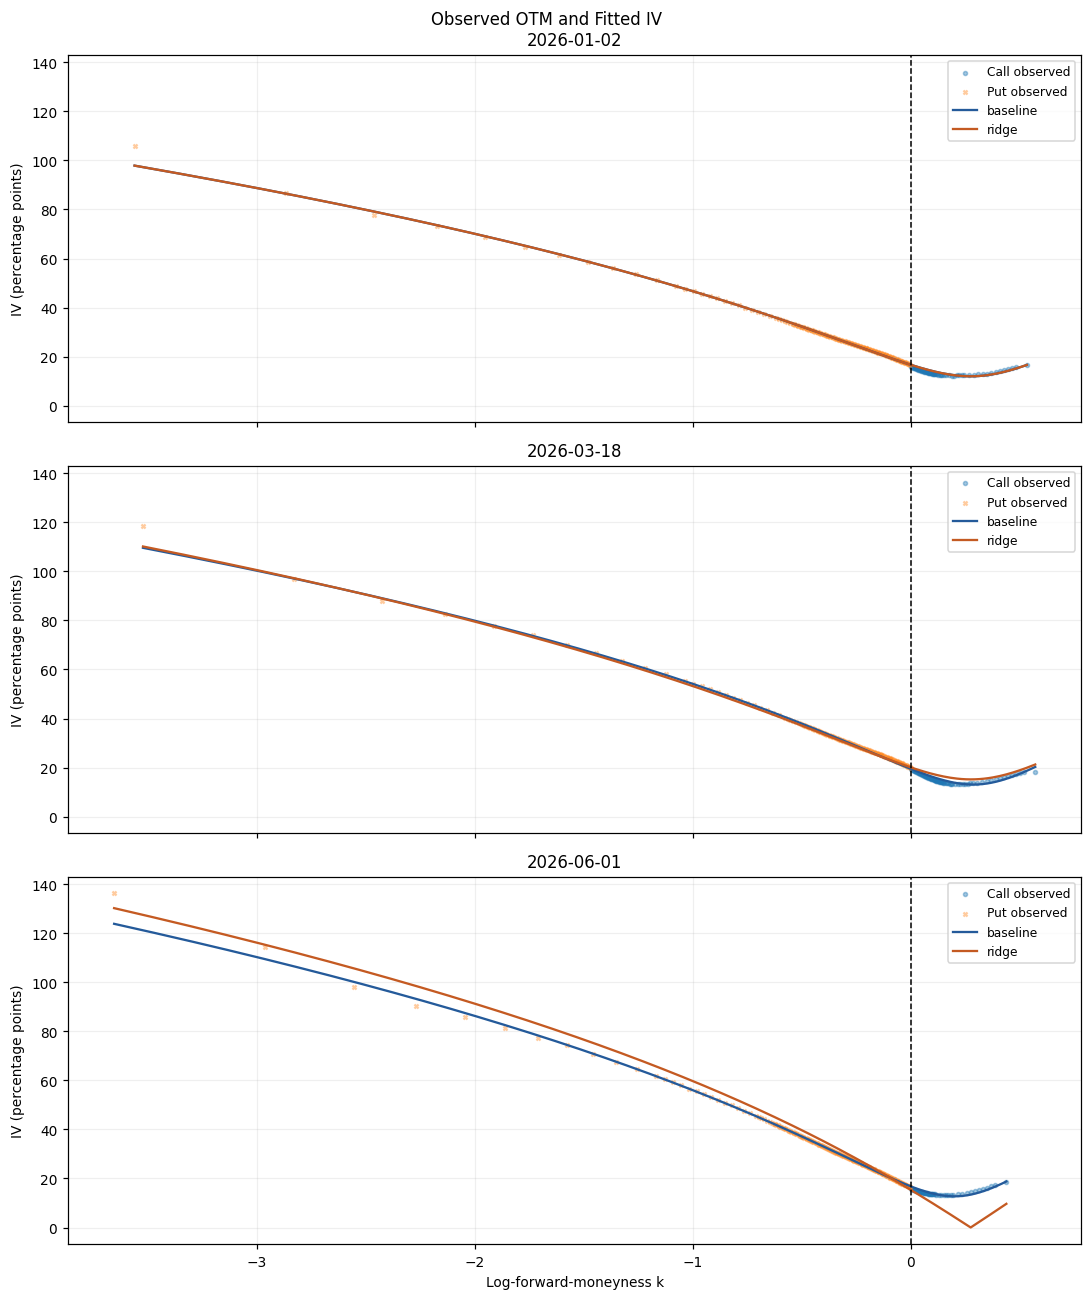

In [103]:
# Compare observed OTM IV with fitted baseline and ridge curves
fig, axes = plt.subplots(3, 1, figsize=(10, 12), sharex=True, sharey=True)

for ax, date in zip(axes, representative_dates):
    observed = sample[sample["pricedate"] == date]

    for side, marker in [("Call", "o"), ("Put", "x")]:
        group = observed[observed["option_type"] == side]

        ax.scatter(
            group["k"], 100 * group["iv_decimal"],
            s=7, alpha=0.4, marker=marker,
            label=side + " observed"
        )

    for model in ["baseline", "ridge"]:
        curve = representative_curves[
            (representative_curves["pricedate"] == date) &
            (representative_curves["model"] == model)
        ]

        ax.plot(
            curve["k"], curve["iv_pp"],
            color=COLORS[model], label=model
        )

    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.set(
        title=date.strftime("%Y-%m-%d"),
        ylabel="IV (percentage points)"
    )
    ax.legend(fontsize=8)

axes[-1].set_xlabel("Log-forward-moneyness k")

fig.suptitle("Observed OTM and Fitted IV")
plt.tight_layout()
save_figure(fig, "02_representative_iv")

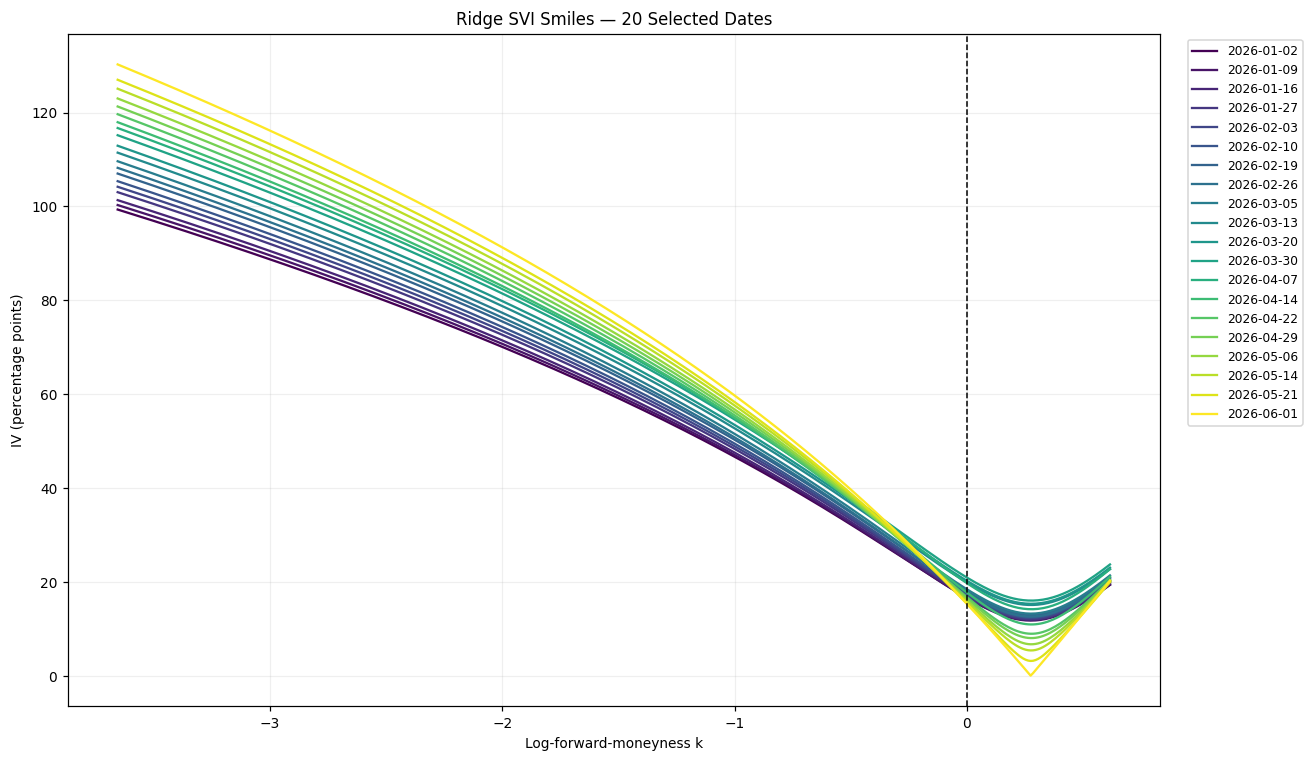

In [118]:
# Plot 20 ridge SVI smiles evenly across the sample
selected_dates = [days[i] for i in np.linspace(0, len(days)-1, 20, dtype=int)]

fig, ax = plt.subplots(figsize=(12, 7))
cmap = plt.cm.viridis

k_grid = np.linspace(sample["k"].min(), sample["k"].max(), 401)

for i, date in enumerate(selected_dates):
    row = ridge[ridge["pricedate"] == date].iloc[0]
    T = daily_inputs[date]["T"].iloc[0]

    params = [row["a"], row["b"], row["rho"], row["m"], row["s"]]
    w = svi(k_grid, params)
    iv_pp = 100 * np.sqrt(np.maximum(w, 0) / T)

    ax.plot(
        k_grid, iv_pp,
        color=cmap(i / 19),
        linewidth=1.5,
        label=pd.Timestamp(date).strftime("%Y-%m-%d")
    )

ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Log-forward-moneyness k")
ax.set_ylabel("IV (percentage points)")
ax.set_title("Ridge SVI Smiles — 20 Selected Dates")
ax.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

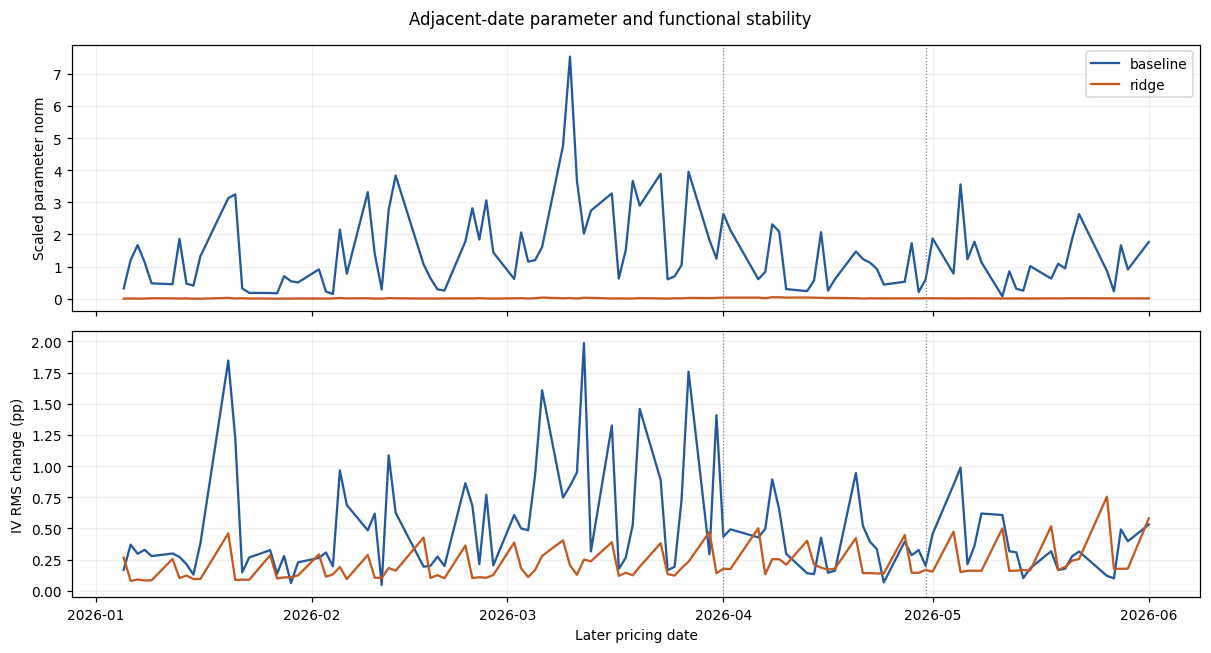

In [104]:
# Compare adjacent-date parameter and fitted-IV changes.
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for ax, field, ylabel in zip(axes, ["parameter_norm", "functional_iv_step_pp"],
                            ["Scaled parameter norm", "IV RMS change (pp)"]):
    for model, group in steps.groupby("model", sort=False):
        ax.plot(group["pricedate"], group[field], color=COLORS[model], label=model)
    ax.set_ylabel(ylabel)
    mark_splits(ax)
axes[0].legend()
axes[1].set_xlabel("Later pricing date")
fig.suptitle("Adjacent-date parameter and functional stability")
save_figure(fig, "07_temporal_stability")

## Call–put consistency and segmented fit

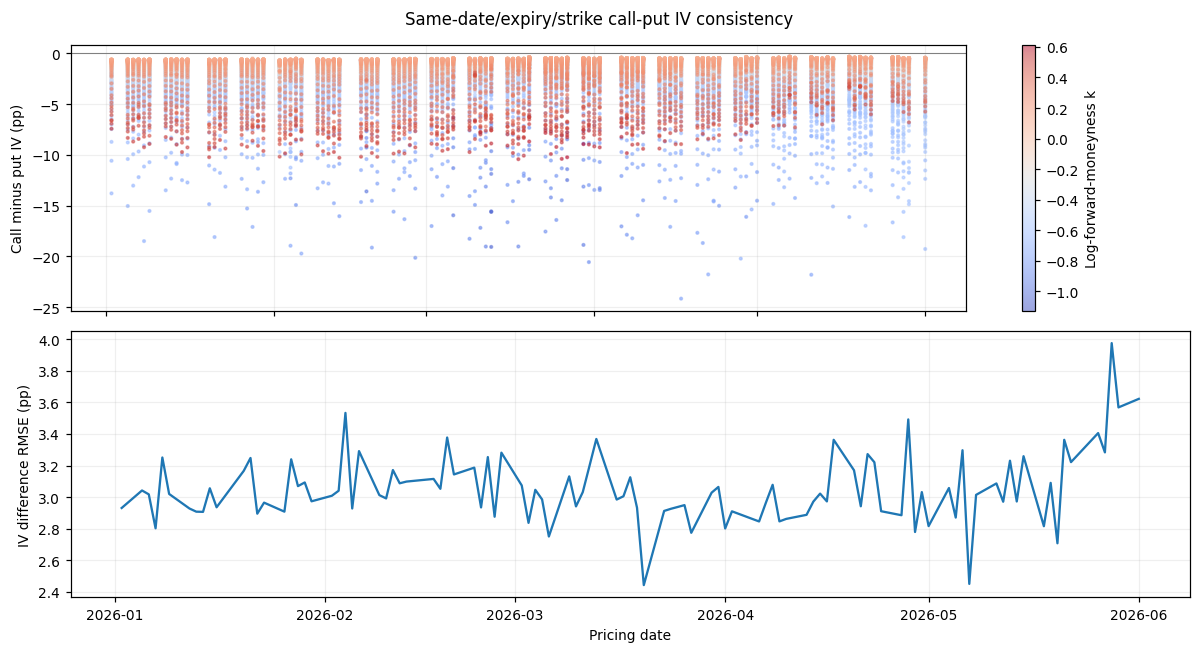

In [105]:
# Show matched call-minus-put IV differences and daily RMSE.
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
points = axes[0].scatter(pairs["pricedate"], pairs["delta_iv_pp"], c=pairs["k"],
                         s=3, alpha=0.5, cmap="coolwarm")
fig.colorbar(points, ax=axes[0], label="Log-forward-moneyness k")
axes[0].axhline(0, color="grey", linewidth=0.7)
axes[0].set_ylabel("Call minus put IV (pp)")
axes[1].plot(pair_daily["pricedate"], pair_daily["rmse"])
axes[1].set(ylabel="IV difference RMSE (pp)", xlabel="Pricing date")
fig.suptitle("Same-date/expiry/strike call-put IV consistency")
save_figure(fig, "09_call_put_iv")

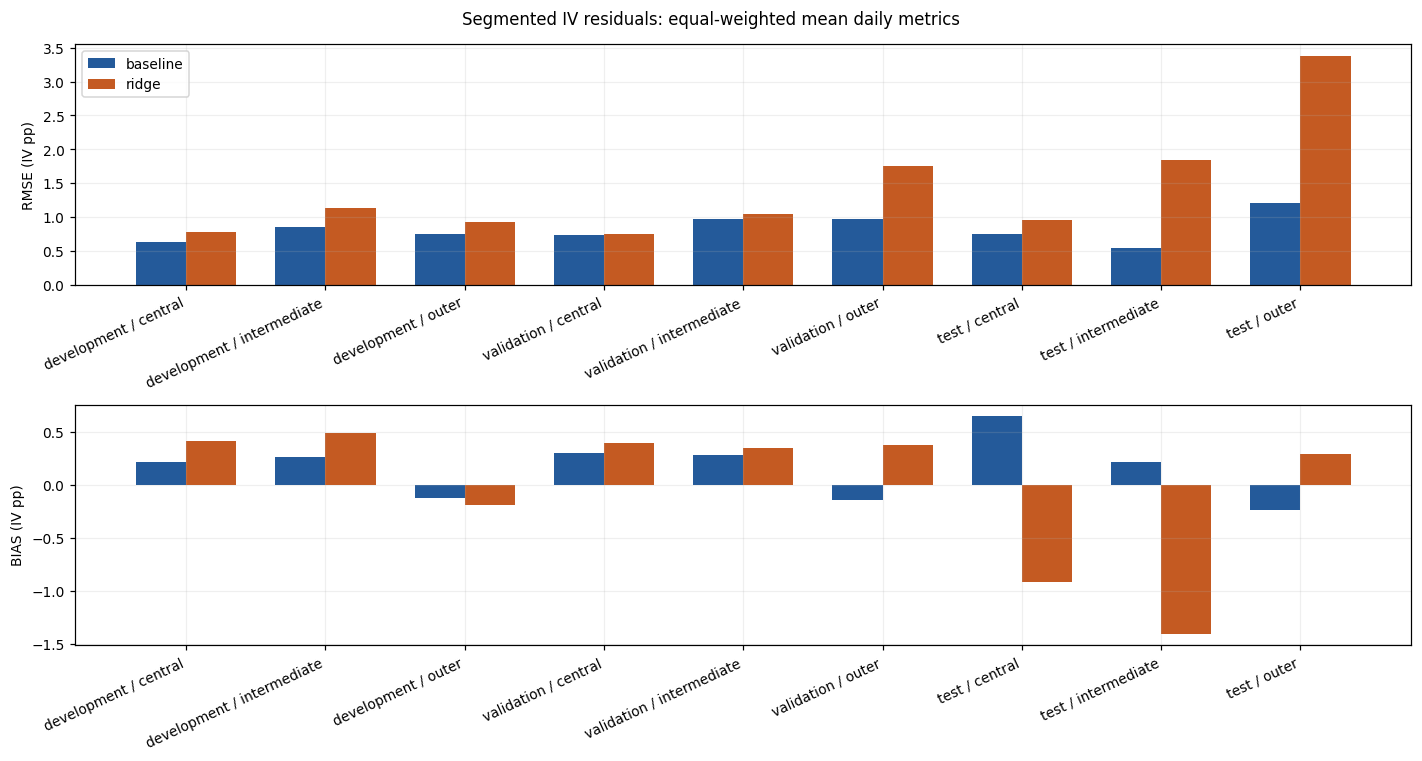

In [106]:
# Compare baseline and ridge mean-daily segmented IV errors on the common sample.
segment_periods = segments[(segments["granularity"] == "period")
                           & (segments["sample"] == "common")
                           & (segments["side"] == "combined")]
labels = [(period, region) for period in ["development", "validation", "test"]
          for region in ["central", "intermediate", "outer"]]
x = np.arange(len(labels))
fig, axes = plt.subplots(2, 1, figsize=(13, 7))
for ax, metric in zip(axes, ["rmse", "bias"]):
    for j, model in enumerate(["baseline", "ridge"]):
        group = segment_periods[segment_periods["model"] == model]
        values = [group[(group["period"] == period) & (group["segment"] == region)][metric].iloc[0]
                  for period, region in labels]
        ax.bar(x + (j - 0.5) * 0.36, values, width=0.36,
               label=model, color=COLORS[model])
    ax.set_xticks(x, [period + " / " + region for period, region in labels],
                  rotation=25, ha="right")
    ax.set_ylabel(metric.upper() + " (IV pp)")
axes[0].legend()
fig.suptitle("Segmented IV residuals: equal-weighted mean daily metrics")
save_figure(fig, "10_segmented_residuals")

## Validation scores

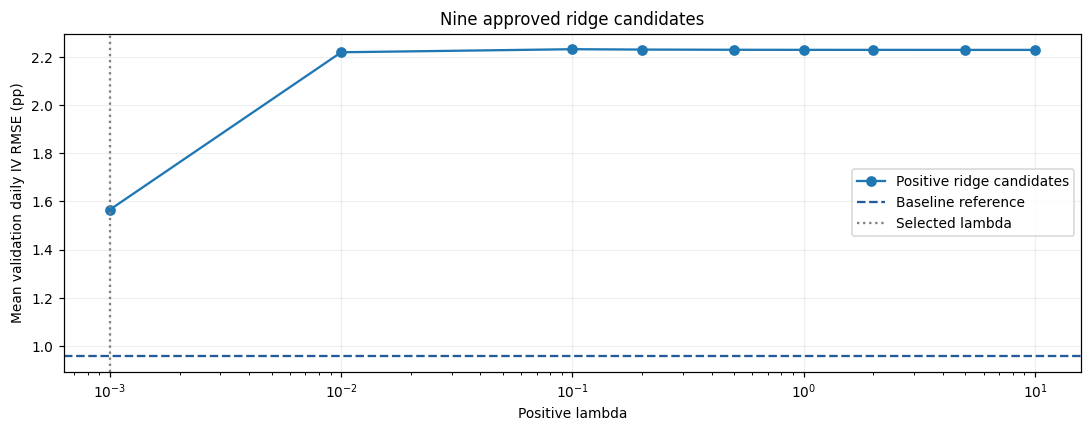

In [107]:
# Compare ridge validation scores against the baseline reference.
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(lambda_scores["lambda_value"], lambda_scores["mean_validation_daily_iv_rmse_pp"],
        "o-", label="Positive ridge candidates")
ax.axhline(baseline_validation_rmse, color=COLORS["baseline"], linestyle="--",
           label="Baseline reference")
if selected_lambda is not None:
    ax.axvline(selected_lambda, color="grey", linestyle=":", label="Selected lambda")
for _, score in lambda_scores.iterrows():
    if not score["eligible"]:
        ax.annotate("ineligible", (score["lambda_value"], 0), rotation=90)
ax.set(xscale="log", xlabel="Positive lambda", ylabel="Mean validation daily IV RMSE (pp)",
       title="Nine approved ridge candidates")
ax.legend()
save_figure(fig, "12_validation_scores")

## Available result tables

In [108]:
# Display the main error and stability summaries from the evaluation sections.
display(calibration_summary[(calibration_summary["sample"] == "common")
                            & (calibration_summary["measure"] == "iv")]
        [["model", "period", "n_valid", "rmse", "mae", "bias"]])
display(stability[(stability["period"] == "all")
                  & stability["metric"].isin(["parameter_norm", "functional_iv_step_pp"])]
        [["model", "metric", "n_valid", "mean", "median", "q95", "max"]])
display(pair_summary[["period", "n_valid", "rmse", "mae", "bias", "max_abs"]])
display(segment_periods[["model", "period", "segment", "n_valid", "rmse", "mae", "bias"]])
display(lambda_scores[["lambda_value", "eligible", "mean_validation_daily_iv_rmse_pp"]])

,model,period,n_valid,rmse,mae,bias
12,baseline,all,22116,0.863103,0.480993,0.006289
13,baseline,development,12902,0.767710,0.482966,0.013519
14,baseline,validation,4300,0.957226,0.547622,0.011982
15,baseline,test,4914,1.042032,0.414949,-0.018935
28,ridge,all,22116,1.495812,1.022946,0.051454
29,ridge,development,12902,0.976018,0.669236,0.051686
30,ridge,validation,4300,1.565870,1.098000,0.374699
31,ridge,test,4914,2.873370,1.935458,-0.243052


,model,metric,n_valid,mean,median,q95,max
5,baseline,parameter_norm,102,1.453312,1.129014,3.665491,7.537389
6,baseline,functional_iv_step_pp,102,0.493630,0.327506,1.404359,1.986968
33,ridge,parameter_norm,102,0.012412,0.009726,0.033644,0.045060
34,ridge,functional_iv_step_pp,102,0.208680,0.165077,0.474094,0.754556


,period,n_valid,rmse,mae,bias,max_abs
0,all,20043,3.053424,2.068979,-2.068979,15.230183
1,development,11772,3.035924,2.069655,-2.069655,14.939762
2,validation,3920,3.009894,2.010381,-2.010381,16.518688
3,test,4351,3.141520,2.120377,-2.120377,14.864072


,model,period,segment,n_valid,rmse,mae,bias
1708,baseline,all,central,2944,0.670897,0.563047,0.322304
1709,baseline,development,central,1708,0.624626,0.519808,0.212180
1710,baseline,validation,central,569,0.727328,0.597032,0.296630
1711,baseline,test,central,667,0.747890,0.652041,0.650989
1815,baseline,all,intermediate,5183,0.811427,0.743123,0.253328
1816,baseline,development,intermediate,3109,0.854232,0.798592,0.260127
1817,baseline,validation,intermediate,1002,0.970072,0.896984,0.281706
1818,baseline,test,intermediate,1072,0.548520,0.449450,0.208680
1922,baseline,all,outer,13989,0.893100,0.363638,-0.153084
1923,baseline,development,outer,8085,0.753012,0.353069,-0.124759


,lambda_value,eligible,mean_validation_daily_iv_rmse_pp
0,10.000,True,2.228969
1,5.000,True,2.228985
2,2.000,True,2.229072
3,1.000,True,2.229196
4,0.500,True,2.229469
5,0.200,True,2.230308
6,0.100,True,2.231788
7,0.010,True,2.219132
8,0.001,True,1.565870


In [110]:
# Summarize calibration availability and optimiser outcomes.
execution_rows = []
parameter_rows = []
for model, path in states.items():
    available = path[path["fit_status"] == "available"]
    attempts = (baseline_attempts if model == "baseline" else
                ridge_attempts[ridge_attempts["lambda_value"] == selected_lambda])
    execution_rows.append({
        "model": model, "expected_dates": len(days), "available_dates": len(available),
        "unavailable_dates": len(days) - len(available), "attempts": len(attempts),
        "eligible_attempts": int(attempts["eligible"].sum()),
        "numerical_exceptions": int((attempts["outcome"] == "numerical_exception").sum()),
        "nonconverged": int((attempts["outcome"] == "nonconverged_finite_feasible").sum()),
        "selected_b_zero": int((available["b"] == 0).sum()),
        "selected_v_zero": int((available["q_v"] == 0).sum())
    })
    summary = available[RAW + ["q_v", "raw_minimum_variance"]].describe().T
    parameter_rows.append(summary.rename_axis("parameter").reset_index().assign(model=model))
execution_summary = pd.DataFrame(execution_rows)
parameter_summary = pd.concat(parameter_rows, ignore_index=True)
ridge_attempt_summary = (ridge_attempts.groupby(["lambda_value", "split", "outcome"], sort=False)
                         .size().rename("attempts").reset_index())
export("model_execution_summary.csv", execution_summary)
export("model_parameter_summary.csv", parameter_summary)
export("ridge_attempt_summary.csv", ridge_attempt_summary)
display(execution_summary)
display(parameter_summary[["model", "parameter", "count", "mean", "std", "min", "50%", "max"]])

,model,expected_dates,available_dates,unavailable_dates,attempts,eligible_attempts,numerical_exceptions,nonconverged,selected_b_zero,selected_v_zero
0,baseline,103,103,0,2987,2811,176,0,0,0
1,ridge,103,103,0,3060,2073,987,0,0,5


,model,parameter,count,mean,std,min,50%,max
0,baseline,a,103.0,-0.360991,2.346636e-02,-0.413697,-0.362222,-0.300554
1,baseline,b,103.0,0.394900,6.405044e-03,0.381408,0.395445,0.423439
2,baseline,rho,103.0,0.239349,2.620473e-02,0.177688,0.232214,0.290394
3,baseline,m,103.0,0.500000,0.000000e+00,0.500000,0.500000,0.500000
4,baseline,s,103.0,0.972875,5.810160e-02,0.819742,0.970259,1.099742
5,baseline,q_v,103.0,0.011870,1.527004e-03,0.008869,0.012269,0.015479
6,baseline,raw_minimum_variance,103.0,0.011870,1.527004e-03,0.008869,0.012269,0.015479
7,ridge,a,103.0,-0.365487,3.066547e-03,-0.371694,-0.364346,-0.360916
8,ridge,b,103.0,0.391152,4.045424e-04,0.390235,0.391209,0.391842
9,ridge,rho,103.0,0.221706,1.219319e-03,0.219465,0.221835,0.224750
